# Lab 03 – Developing a Tiny Transformer Language Model

**Module:** PUSL3205 – Large Language Models and Generative AI

**Practical Topic:** Transformer Architecture, Language Modelling and Text Generation

**Programming Language:** Python

**Development Environment:** Google Colab

## 1. Introduction

This practical explores the development of a small Transformer-based language model using PyTorch.

The main objective is to understand how Transformer models learn patterns in sequential text and use previously observed characters to predict the next character.

The experiment uses the TinyStories dataset from Hugging Face. A subset of stories is selected to make the training process manageable.

The practical covers dataset preparation, character-level tokenisation, next-character prediction, Transformer architecture implementation, model training, evaluation, story generation, experimentation and model saving.

## 2. Objectives

The objectives of this practical are to:

- Load and explore the TinyStories dataset.
- Understand character-level tokenisation.
- Prepare input and target sequences for language modelling.
- Implement a decoder-only Transformer architecture.
- Apply masked multi-head self-attention.
- Train the model using cross-entropy loss and backpropagation.
- Monitor training and validation performance.
- Calculate validation loss and perplexity.
- Generate new stories from starting prompts.
- Compare different Transformer configurations.
- Save trained weights and model configurations.

## 3. Required Libraries

Python, PyTorch, Hugging Face Datasets, NumPy, Pandas and Matplotlib are used for implementing and evaluating the language model.

In [1]:
%pip install -q torch datasets numpy pandas matplotlib

## 4. Environment Configuration

The required Python libraries are imported to support dataset loading, text preprocessing, numerical computation, Transformer implementation, model training and visualisation.

PyTorch is used to implement the neural network architecture and perform automatic differentiation.

A fixed random seed is configured to improve the reproducibility of the experiments.

The available computing device is detected automatically. CUDA is used when a compatible GPU is available, otherwise the model runs on the CPU.

The project directory is organised into separate folders for the dataset, executed notebook, experimental results, screenshots and saved model files.

In [2]:
import os
import json
import math
import time
import random
import shutil

from pathlib import Path
from itertools import islice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
from IPython.display import display

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE INFORMATION")
print("=" * 55)

print("Selected device:", device)
print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

# Create project folders
ROOT = Path("/content/Lab-03-Tiny-Transformer")

DATA_DIR = ROOT / "dataset"
NOTEBOOK_DIR = ROOT / "notebooks"
RESULTS_DIR = ROOT / "results"
SCREENSHOT_DIR = ROOT / "screenshots"
MODEL_DIR = ROOT / "saved-model"

for folder in [
    ROOT,
    DATA_DIR,
    NOTEBOOK_DIR,
    RESULTS_DIR,
    SCREENSHOT_DIR,
    MODEL_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("\nPROJECT FOLDERS")
print("=" * 55)

for folder in [
    DATA_DIR,
    NOTEBOOK_DIR,
    RESULTS_DIR,
    SCREENSHOT_DIR,
    MODEL_DIR
]:
    print(folder)

DEVICE INFORMATION
Selected device: cuda
PyTorch version: 2.14.1+cu130
GPU: Tesla T4

PROJECT FOLDERS
/content/Lab-03-Tiny-Transformer/dataset
/content/Lab-03-Tiny-Transformer/notebooks
/content/Lab-03-Tiny-Transformer/results
/content/Lab-03-Tiny-Transformer/screenshots
/content/Lab-03-Tiny-Transformer/saved-model


## 5. Dataset Loading and Exploration

### 5.1 Dataset Description

The TinyStories dataset is used to train a small Transformer language model.

TinyStories contains short stories written using relatively simple vocabulary and sentence structures, making it suitable for experimenting with compact language models.

The dataset is available through Hugging Face under the identifier `roneneldan/TinyStories`.

For this experiment, a subset of 1,500 stories is selected from the training split.

Streaming is used to load only the required number of stories rather than downloading the entire dataset.

The selected stories are inspected to understand their content, structure and approximate length.

In [3]:
DATASET_NAME = "roneneldan/TinyStories"

NUM_STORIES = 1500

# Stream the dataset from Hugging Face
dataset_stream = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

# Select a manageable subset
examples = list(
    islice(dataset_stream, NUM_STORIES)
)

stories = [
    example["text"].strip()
    for example in examples
    if isinstance(example.get("text"), str)
    and example["text"].strip()
]

if len(stories) < 100:
    raise ValueError(
        "Insufficient stories loaded. "
        "Check the dataset connection."
    )

print("DATASET INFORMATION")
print("=" * 55)

print("Dataset:", DATASET_NAME)
print("Selected stories:", len(stories))

print("\nSAMPLE STORIES")

for i, story in enumerate(stories[:3], start=1):

    print(f"\n--- Story {i} ---")
    print(story[:700])
    print("-" * 55)

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

DATASET INFORMATION
Dataset: roneneldan/TinyStories
Selected stories: 1500

SAMPLE STORIES

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together
-------------------------------------------------------

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car

### 5.2 Exploratory Analysis of Story Lengths

The selected stories are analysed to understand differences in their lengths.

For each story, the number of words and characters is calculated.

Descriptive statistics are generated to examine the minimum, maximum, mean and distribution of story lengths.

A histogram is created to visualise the variation in story length across the selected subset.

This analysis helps inform later decisions about tokenisation, context-window size and training-sequence preparation.

STORY LENGTH STATISTICS


,Story,Word Count,Character Count
count,1500.00,1500.00,1500.00
mean,750.50,169.52,867.30
std,433.16,74.68,371.24
min,1.00,61.00,274.00
25%,375.75,129.00,661.00
50%,750.50,150.00,775.50
75%,1125.25,180.00,935.00
max,1500.00,837.00,4123.00



Sample story lengths:


,Story,Word Count,Character Count
0,1,134,701
1,2,142,705
2,3,168,822
3,4,163,845
4,5,129,638
5,6,138,657
6,7,144,723
7,8,148,750
8,9,156,774
9,10,123,596


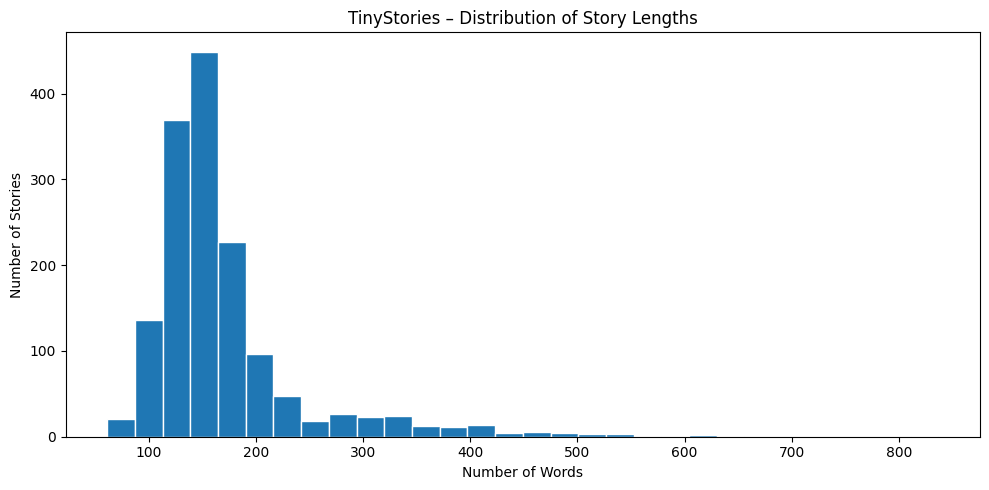

In [4]:
story_lengths = pd.DataFrame({

    "Story": range(1, len(stories) + 1),

    "Word Count": [
        len(story.split())
        for story in stories
    ],

    "Character Count": [
        len(story)
        for story in stories
    ]

})

print("STORY LENGTH STATISTICS")
print("=" * 55)

display(story_lengths.describe().round(2))

print("\nSample story lengths:")
display(story_lengths.head(10))

plt.figure(figsize=(10, 5))

plt.hist(
    story_lengths["Word Count"],
    bins=30,
    edgecolor="white"
)

plt.title("TinyStories – Distribution of Story Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Stories")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "01-story-length-distribution.png",
    dpi=300
)

plt.show()

story_lengths.to_csv(
    RESULTS_DIR / "story-length-statistics.csv",
    index=False
)

## 6. Text Preprocessing and Character-Level Tokenisation

The selected stories are divided into training and validation groups before constructing the encoded text sequences.

A 90:10 split is used to separate the stories for model development and evaluation.

The split is performed at the story level so that the same story cannot contribute overlapping character sequences to both datasets.

Character-level tokenisation is implemented by creating a vocabulary from the unique characters appearing in the training stories.

Two mappings are constructed:

- `stoi`: Converts characters into integer token IDs.
- `itos`: Converts integer token IDs back into characters.

The token ID zero is reserved for characters not present in the training vocabulary.

This approach allows the model to process text numerically without using a pretrained tokenizer.

In [5]:
# Shuffle story indices reproducibly
indices = list(range(len(stories)))

random.Random(SEED).shuffle(indices)

split_index = int(0.90 * len(indices))

training_indices = indices[:split_index]
validation_indices = indices[split_index:]

train_stories = [
    stories[i]
    for i in training_indices
]

val_stories = [
    stories[i]
    for i in validation_indices
]

# Join stories only after splitting
train_text = "\n".join(train_stories) + "\n"
val_text = "\n".join(val_stories) + "\n"

# Build vocabulary using training text
chars = sorted(set(train_text))

stoi = {
    character: i + 1
    for i, character in enumerate(chars)
}

itos = {
    token_id: character
    for character, token_id in stoi.items()
}

# Unknown-character token
itos[0] = "?"

vocab_size = len(stoi) + 1

def encode(text):
    return [
        stoi.get(character, 0)
        for character in text
    ]

def decode(token_ids):
    return "".join(
        itos.get(int(token_id), "?")
        for token_id in token_ids
    )

# Encode the text
train_data = torch.tensor(
    encode(train_text),
    dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text),
    dtype=torch.long
)

print("TOKENISATION RESULTS")
print("=" * 55)

print("Training stories:", len(train_stories))
print("Validation stories:", len(val_stories))

print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

print("Vocabulary size:", vocab_size)

print("\nSample encoding:")

example = "Once upon a time"

print("Original:", example)
print("Encoded :", encode(example))
print("Decoded :", decode(encode(example)))

print(
    "\nUnknown validation characters:",
    int((val_data == 0).sum())
)

# Save selected stories with split labels
with open(
    DATA_DIR / "selected_stories.jsonl",
    "w",
    encoding="utf-8"
) as file:

    for split_name, selected in [
        ("train", train_stories),
        ("validation", val_stories)
    ]:

        for story in selected:

            file.write(
                json.dumps(
                    {
                        "split": split_name,
                        "text": story
                    },
                    ensure_ascii=False
                ) + "\n"
            )

TOKENISATION RESULTS
Training stories: 1350
Validation stories: 150
Training characters: 1175835
Validation characters: 126619
Vocabulary size: 78

Sample encoding:
Original: Once upon a time
Encoded : [33, 58, 47, 49, 2, 65, 60, 59, 58, 2, 45, 2, 64, 53, 57, 49]
Decoded : Once upon a time

Unknown validation characters: 0


## 7. Preparing Training Data for Next-Character Prediction

The Transformer is trained using next-character prediction.

Each input sequence contains a fixed number of consecutive characters. The corresponding target sequence contains the same characters shifted one position to the left.

For example:

Input: `hell`

Target: `ello`

This allows the model to learn to predict the next character from the preceding context.

A context length of 128 characters and a batch size of 32 are used for the initial experiment.

Randomly selected sequences are grouped into mini-batches to support efficient training.

In [6]:
BATCH_SIZE = 32
BLOCK_SIZE = 128

def get_batch(split):

    if split == "train":
        source = train_data

    elif split == "val":
        source = val_data

    else:
        raise ValueError(
            "Split must be 'train' or 'val'"
        )

    if len(source) <= BLOCK_SIZE + 1:
        raise ValueError(
            "Not enough text for the selected block size"
        )

    # Random starting positions
    starts = torch.randint(
        0,
        len(source) - BLOCK_SIZE,
        (BATCH_SIZE,)
    )

    # Input sequences
    x = torch.stack([
        source[i:i + BLOCK_SIZE]
        for i in starts
    ])

    # Next-character targets
    y = torch.stack([
        source[i + 1:i + BLOCK_SIZE + 1]
        for i in starts
    ])

    return x.to(device), y.to(device)


sample_x, sample_y = get_batch("train")

print("TRAINING DATA PREPARATION")
print("=" * 55)

print("Batch size:", BATCH_SIZE)
print("Block size:", BLOCK_SIZE)

print("Input shape:", tuple(sample_x.shape))
print("Target shape:", tuple(sample_y.shape))

print("\nExample input:")
print(
    decode(sample_x[0, :60].cpu().tolist())
)

print("\nCorresponding target:")
print(
    decode(sample_y[0, :60].cpu().tolist())
)

TRAINING DATA PREPARATION
Batch size: 32
Block size: 128
Input shape: (32, 128)
Target shape: (32, 128)

Example input:
at was wrong. Tim told her about Sam's cart. His mom said, "

Corresponding target:
t was wrong. Tim told her about Sam's cart. His mom said, "I


## 8. Building the Transformer Architecture

A decoder-only Transformer language model is implemented using PyTorch.

The architecture includes the following components:

1. **Token Embeddings:** Convert character IDs into dense numerical representations.

2. **Positional Embeddings:** Provide information about character positions within each input sequence.

3. **Masked Multi-Head Self-Attention:** Allows the model to learn relationships between previous characters while preventing attention to future positions.

4. **Feed-Forward Network:** Applies nonlinear transformations to the representations produced by the attention mechanism.

5. **Residual Connections:** Support information flow and gradient propagation through the network.

6. **Layer Normalisation:** Helps maintain stable activations during training.

7. **Output Layer:** Converts the final representations into next-character prediction scores.

A causal attention mask is applied to ensure that each position can attend only to itself and preceding positions.

This is essential for autoregressive language modelling, where future characters must not be visible during prediction.

In [7]:
class TransformerBlock(nn.Module):

    def __init__(
        self,
        d_model,
        n_heads,
        dropout
    ):
        super().__init__()

        # Layer normalisation
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # Multi-head self-attention
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        # Feed-forward neural network
        self.feed_forward = nn.Sequential(

            nn.Linear(d_model, 4 * d_model),

            nn.GELU(),

            nn.Linear(4 * d_model, d_model),

            nn.Dropout(dropout)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        sequence_length = x.size(1)

        # True means the position is masked
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                dtype=torch.bool,
                device=x.device
            ),
            diagonal=1
        )

        # Masked self-attention
        normalized = self.norm1(x)

        attention_output, _ = self.attention(
            normalized,
            normalized,
            normalized,
            attn_mask=causal_mask,
            need_weights=False
        )

        # Residual connection
        x = x + self.dropout(attention_output)

        # Feed-forward + residual connection
        x = x + self.feed_forward(
            self.norm2(x)
        )

        return x


class TinyTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        block_size,
        d_model=128,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        if d_model % n_heads != 0:
            raise ValueError(
                "Embedding dimension must be divisible "
                "by the number of attention heads"
            )

        self.block_size = block_size

        # Character embeddings
        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        # Positional embeddings
        self.position_embedding = nn.Embedding(
            block_size,
            d_model
        )

        # Transformer blocks
        self.blocks = nn.Sequential(*[
            TransformerBlock(
                d_model,
                n_heads,
                dropout
            )
            for _ in range(n_layers)
        ])

        self.final_norm = nn.LayerNorm(d_model)

        # Character prediction layer
        self.output_layer = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, idx, targets=None):

        batch_size, sequence_length = idx.shape

        if sequence_length > self.block_size:
            raise ValueError(
                "Input exceeds the model context length"
            )

        positions = torch.arange(
            sequence_length,
            device=idx.device
        )

        # Token + positional embeddings
        x = (
            self.token_embedding(idx)
            +
            self.position_embedding(positions)
        )

        # Transformer processing
        x = self.blocks(x)

        x = self.final_norm(x)

        logits = self.output_layer(x)

        loss = None

        if targets is not None:

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(
        self,
        idx,
        max_new_tokens=300,
        temperature=0.85,
        top_k=30
    ):

        self.eval()

        for _ in range(max_new_tokens):

            context = idx[:, -self.block_size:]

            logits, _ = self(context)

            # Scores for the next character
            next_logits = logits[:, -1, :]

            next_logits = next_logits / max(
                temperature,
                1e-5
            )

            if top_k is not None:

                k = min(
                    top_k,
                    next_logits.size(-1)
                )

                values, _ = torch.topk(
                    next_logits,
                    k
                )

                threshold = values[:, [-1]]

                next_logits = next_logits.masked_fill(
                    next_logits < threshold,
                    float("-inf")
                )

            probabilities = F.softmax(
                next_logits,
                dim=-1
            )

            next_character = torch.multinomial(
                probabilities,
                num_samples=1
            )

            idx = torch.cat(
                [idx, next_character],
                dim=1
            )

        return idx


print("Transformer architecture created successfully.")

Transformer architecture created successfully.


## 9. Model Initialisation and Training Configuration

The Transformer model is initialised using a configuration suitable for a small character-level language modelling experiment.

The baseline model uses an embedding dimension of 128, four attention heads and two Transformer layers.

The model parameters are initialised before training.

Cross-entropy loss is used to measure the difference between predicted next-character probabilities and the corresponding target characters.

The AdamW optimiser is selected to update the model parameters during backpropagation.

A learning rate of 0.0003 and weight decay of 0.01 are used.

The experiment uses six epochs, with a fixed number of randomly sampled training batches per epoch.

This setup allows the model to learn character patterns while keeping the experiment manageable.

In [8]:
BASE_CONFIG = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 2,
    "dropout": 0.1
}

LEARNING_RATE = 0.0003
WEIGHT_DECAY = 0.01

EPOCHS = 6
STEPS_PER_EPOCH = 60
EVAL_BATCHES = 12

# Weight initialisation
def initialize_weights(module):

    if isinstance(module, nn.Linear):

        nn.init.normal_(
            module.weight,
            mean=0.0,
            std=0.02
        )

        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.Embedding):

        nn.init.normal_(
            module.weight,
            mean=0.0,
            std=0.02
        )

# Create the baseline model
model = TinyTransformer(
    **BASE_CONFIG
).to(device)

model.apply(initialize_weights)

# Create the optimiser
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Count trainable parameters
parameter_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("MODEL INITIALISATION")
print("=" * 55)

print(model)

print("\nTRAINING CONFIGURATION")
print("=" * 55)

print("Embedding dimension:", BASE_CONFIG["d_model"])
print("Attention heads:", BASE_CONFIG["n_heads"])
print("Transformer layers:", BASE_CONFIG["n_layers"])

print("Trainable parameters:", parameter_count)

print("Loss function: Cross-Entropy")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)

print("Epochs:", EPOCHS)
print("Steps per epoch:", STEPS_PER_EPOCH)
print("Device:", device)

MODEL INITIALISATION
TinyTransformer(
  (token_embedding): Embedding(78, 128)
  (position_embedding): Embedding(128, 128)
  (blocks): Sequential(
    (0): TransformerBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (feed_forward): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
        (3): Dropout(p=0.1, inplace=False)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): Multihea

## 10. Training the Transformer Language Model

The Transformer is trained using next-character prediction.

During each training step, a batch of input sequences and corresponding target sequences is selected.

The model produces prediction scores for the next character at every position.

Cross-entropy loss is calculated to measure prediction error. Backpropagation is then used to compute gradients, and the AdamW optimiser updates the trainable parameters.

Gradient clipping is applied to reduce the risk of excessively large gradient updates.

At the end of each epoch, the model is evaluated on validation data.

Training and validation losses are recorded to monitor the learning process and identify potential underfitting or overfitting.

Each epoch consists of a fixed number of sampled mini-batches rather than a complete pass through every possible training sequence.

In [9]:
@torch.no_grad()
def evaluate_loss(network, split, batches=EVAL_BATCHES):

    network.eval()

    losses = []

    for _ in range(batches):

        xb, yb = get_batch(split)

        _, loss = network(xb, yb)

        losses.append(loss.item())

    return float(np.mean(losses))


def train_network(
    network,
    optimiser,
    epochs,
    model_name
):

    history = []

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        network.train()

        epoch_losses = []

        for step in range(STEPS_PER_EPOCH):

            xb, yb = get_batch("train")

            logits, loss = network(xb, yb)

            optimiser.zero_grad(
                set_to_none=True
            )

            loss.backward()

            # Control gradient magnitude
            torch.nn.utils.clip_grad_norm_(
                network.parameters(),
                max_norm=1.0
            )

            optimiser.step()

            epoch_losses.append(
                loss.item()
            )

        train_loss = float(
            np.mean(epoch_losses)
        )

        validation_loss = evaluate_loss(
            network,
            "val"
        )

        history.append({
            "Epoch": epoch,
            "Training Loss": train_loss,
            "Validation Loss": validation_loss
        })

        print(
            f"{model_name} | "
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {validation_loss:.4f}"
        )

    elapsed = time.time() - start_time

    print("\nTraining completed.")
    print(f"Training duration: {elapsed:.2f} seconds")

    return pd.DataFrame(history)


# Train baseline Transformer
history = train_network(
    model,
    optimizer,
    EPOCHS,
    "Baseline Transformer"
)

print("\nTRAINING HISTORY")

display(history.round(4))

history.to_csv(
    RESULTS_DIR / "02-training-history.csv",
    index=False
)

Baseline Transformer | Epoch 1/6 | Train Loss: 3.1599 | Validation Loss: 2.6512
Baseline Transformer | Epoch 2/6 | Train Loss: 2.5356 | Validation Loss: 2.4125
Baseline Transformer | Epoch 3/6 | Train Loss: 2.3941 | Validation Loss: 2.2979
Baseline Transformer | Epoch 4/6 | Train Loss: 2.3209 | Validation Loss: 2.2386
Baseline Transformer | Epoch 5/6 | Train Loss: 2.2452 | Validation Loss: 2.1611
Baseline Transformer | Epoch 6/6 | Train Loss: 2.1751 | Validation Loss: 2.0615

Training completed.
Training duration: 5.06 seconds

TRAINING HISTORY


,Epoch,Training Loss,Validation Loss
0,1,3.1599,2.6512
1,2,2.5356,2.4125
2,3,2.3941,2.2979
3,4,2.3209,2.2386
4,5,2.2452,2.1611
5,6,2.1751,2.0615


## 11. Monitoring Training Performance

Training and validation loss curves are plotted to observe how the Transformer learns over successive epochs.

Training loss measures prediction error on sampled training sequences.

Validation loss measures prediction error on sequences from stories that were not used for parameter updates.

A reduction in both losses indicates that the model is learning useful patterns from the data.

A large and increasing difference between training and validation loss may indicate overfitting.

The loss curves are saved for later analysis and inclusion in the practical portfolio.

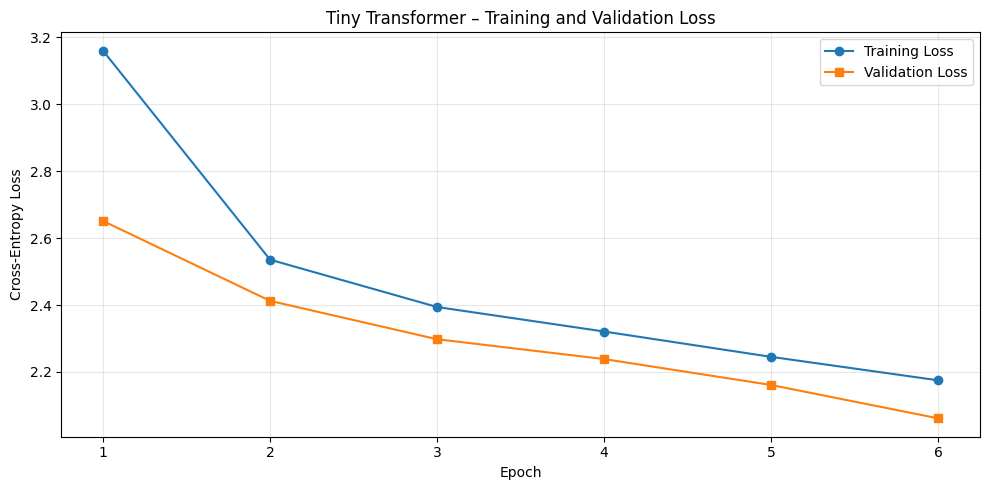

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["Epoch"],
    history["Training Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["Epoch"],
    history["Validation Loss"],
    marker="s",
    label="Validation Loss"
)

plt.title(
    "Tiny Transformer – Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "03-training-validation-loss.png",
    dpi=300
)

plt.show()

## 12. Model Evaluation

The trained Transformer is evaluated using validation loss and perplexity.

Validation loss measures how accurately the model predicts the next character on text that was not used for parameter updates.

Perplexity is calculated by taking the exponential of the average cross-entropy loss.

A lower perplexity indicates that the model assigns greater probability to the correct next characters.

Because this experiment uses character-level tokenisation, the reported perplexity is character-level perplexity and should not be directly compared with perplexity from word-level or subword-level language models.

The evaluation results are recorded for comparison with a second Transformer configuration.

In [11]:
final_train_loss = evaluate_loss(
    model,
    "train",
    batches=40
)

final_validation_loss = evaluate_loss(
    model,
    "val",
    batches=40
)

perplexity = math.exp(
    final_validation_loss
)

print("FINAL MODEL EVALUATION")
print("=" * 55)

print(
    f"Training Loss: {final_train_loss:.4f}"
)

print(
    f"Validation Loss: {final_validation_loss:.4f}"
)

print(
    f"Validation Perplexity: {perplexity:.4f}"
)

evaluation_results = {
    "model": "Baseline Transformer",
    "training_loss": final_train_loss,
    "validation_loss": final_validation_loss,
    "perplexity": perplexity
}

with open(
    RESULTS_DIR / "04-evaluation-results.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        evaluation_results,
        file,
        indent=4
    )

FINAL MODEL EVALUATION
Training Loss: 2.0790
Validation Loss: 2.0664
Validation Perplexity: 7.8966


## 13. Story Generation Using the Trained Transformer

The trained Transformer is used to generate new text from starting prompts.

The generation process is autoregressive: the model predicts one character at a time and appends that character to the existing sequence.

The updated sequence is then used to predict the next character.

Temperature and top-k sampling are applied to control the selection of generated characters.

The experiment uses prompts such as "Once upon a time" to evaluate whether the model has learned useful character patterns and elements of story structure.

The generated outputs are examined for readability, grammatical structure, repetition and overall coherence.

In [12]:
def generate_story(
    network,
    prompt,
    max_new_tokens=300
):

    token_ids = encode(prompt)

    if not token_ids:
        raise ValueError(
            "The prompt must not be empty."
        )

    input_tensor = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    generated_ids = network.generate(
        input_tensor,
        max_new_tokens=max_new_tokens,
        temperature=0.85,
        top_k=30
    )

    generated_text = decode(
        generated_ids[0].cpu().tolist()
    )

    return generated_text


PROMPTS = [
    "Once upon a time",
    "There was a little girl"
]

generated_stories = {}

for prompt in PROMPTS:

    generated_text = generate_story(
        model,
        prompt
    )

    generated_stories[prompt] = generated_text

    print("\n" + "=" * 65)
    print("PROMPT:", prompt)
    print("=" * 65)

    print(generated_text)

with open(
    RESULTS_DIR / "05-generated-stories.txt",
    "w",
    encoding="utf-8"
) as file:

    for prompt, story in generated_stories.items():

        file.write(
            f"PROMPT: {prompt}\n\n"
        )

        file.write(story)

        file.write("\n\n" + "=" * 65 + "\n\n")


PROMPT: Once upon a time
Once upon a timecelelle ay. Suld ara bok loucy bre.

Ong was are groked oot togeh pughe rothank fur aris thene anced tomy.ha daf beithe herrecl was. 

Sut tis uthe now "He bo ther. Thailt was the therd ade mius nad bice the therer was withas gick tas ang to turand heary wimy. Tas, wiLiry lor the wal the afwas heend

PROMPT: There was a little girl
There was a little girle the woreind. He s oto looncke pmand ve im owstorred lbuted in bof arledert he a ow as smay heand bretto wahere was. Eckeerous illyed sod mow erfor ththert wateret to bashcan thert lok niketplin noul sa.


Ontfe!" yougres scthe souret a car a was a wais trof waw sked as bo astunne said mar heres to


## 14. Experimenting with Transformer Configurations

An additional experiment is performed to investigate the effect of changing the model architecture.

The baseline Transformer contains two Transformer layers and four attention heads.

A second Transformer is created with three layers while retaining the same embedding dimension, number of attention heads, learning rate, batch size and training budget.

Both models are trained using the same training and validation datasets.

Their parameter counts, training losses, validation losses, perplexities and generated text are compared.

This experiment investigates whether increasing Transformer depth improves predictive performance under the selected training configuration.

A deeper model may have greater representational capacity, but it also requires additional computation and does not necessarily perform better with limited training data or training steps.

In [13]:
# Second model with three Transformer layers
EXPERIMENT_CONFIG = {
    **BASE_CONFIG,
    "n_layers": 3
}

experiment_model = TinyTransformer(
    **EXPERIMENT_CONFIG
).to(device)

experiment_model.apply(initialize_weights)

experiment_optimizer = torch.optim.AdamW(
    experiment_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("EXPERIMENT CONFIGURATION")
print("=" * 55)

print("Baseline layers:", BASE_CONFIG["n_layers"])
print("Experiment layers:", EXPERIMENT_CONFIG["n_layers"])

print(
    "Attention heads:",
    EXPERIMENT_CONFIG["n_heads"]
)

print("\nTraining the experimental model...")

experiment_history = train_network(
    experiment_model,
    experiment_optimizer,
    EPOCHS,
    "Three-Layer Transformer"
)

experiment_history.to_csv(
    RESULTS_DIR / "06-experiment-training-history.csv",
    index=False
)

print("\nEXPERIMENTAL TRAINING HISTORY")

display(experiment_history.round(4))

EXPERIMENT CONFIGURATION
Baseline layers: 2
Experiment layers: 3
Attention heads: 4

Training the experimental model...
Three-Layer Transformer | Epoch 1/6 | Train Loss: 3.1667 | Validation Loss: 2.6504
Three-Layer Transformer | Epoch 2/6 | Train Loss: 2.5324 | Validation Loss: 2.3995
Three-Layer Transformer | Epoch 3/6 | Train Loss: 2.3978 | Validation Loss: 2.3207
Three-Layer Transformer | Epoch 4/6 | Train Loss: 2.3192 | Validation Loss: 2.2299
Three-Layer Transformer | Epoch 5/6 | Train Loss: 2.2326 | Validation Loss: 2.1212
Three-Layer Transformer | Epoch 6/6 | Train Loss: 2.1311 | Validation Loss: 2.0152

Training completed.
Training duration: 5.06 seconds

EXPERIMENTAL TRAINING HISTORY


,Epoch,Training Loss,Validation Loss
0,1,3.1667,2.6504
1,2,2.5324,2.3995
2,3,2.3978,2.3207
3,4,2.3192,2.2299
4,5,2.2326,2.1212
5,6,2.1311,2.0152


### 14.1 Model Performance Comparison

The baseline and experimental Transformer configurations are evaluated using the same validation dataset.

The comparison considers the following factors:

- Number of Transformer layers.
- Number of attention heads.
- Total number of model parameters.
- Final validation cross-entropy loss.
- Validation perplexity.
- Generated text quality.

The resulting table and graph provide evidence of how the model's depth influences performance.

The interpretation should consider both predictive performance and additional model complexity.

TRANSFORMER MODEL COMPARISON


,Model,Layers,Heads,Parameters,Epochs,Validation Loss,Perplexity
0,Baseline – 2 Layers,2,4,433230,6,2.0697,7.9222
1,Experiment – 3 Layers,3,4,631502,6,2.0227,7.5585


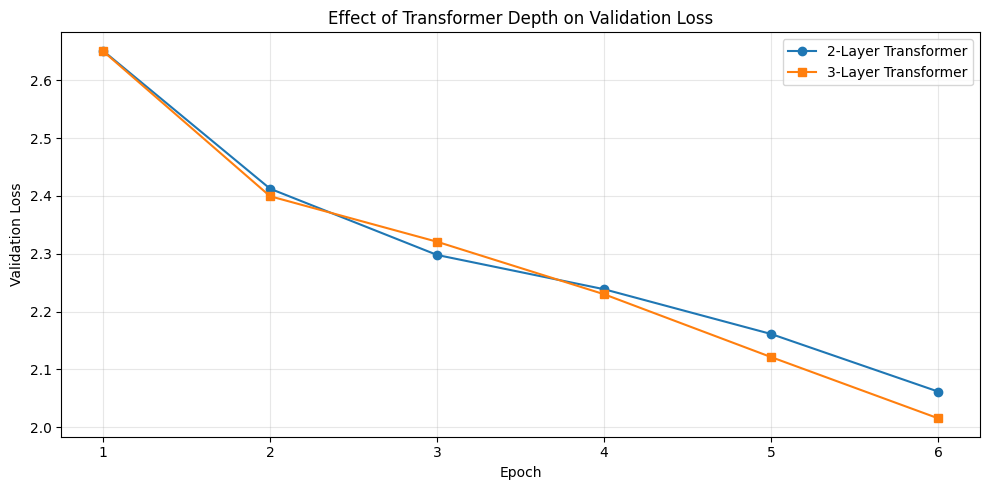


THREE-LAYER MODEL GENERATED STORY
Once upon a time i was, thn the aorhe bend win to we is to haplinthe the are ind ther wereatber me. They tloot atte as froure cand and it tol cous lad to ger den thed soo linceance the cher in wa ne! They ton!

Ont lot ante en fand th
"Therperyy the his care le. Shece uved bie foud so ther tend e weplarte pind ande


316

In [14]:
baseline_val_loss = evaluate_loss(
    model,
    "val",
    batches=40
)

experiment_val_loss = evaluate_loss(
    experiment_model,
    "val",
    batches=40
)

experiment_parameter_count = sum(
    p.numel()
    for p in experiment_model.parameters()
)

comparison_df = pd.DataFrame([

    {
        "Model": "Baseline – 2 Layers",
        "Layers": BASE_CONFIG["n_layers"],
        "Heads": BASE_CONFIG["n_heads"],
        "Parameters": parameter_count,
        "Epochs": EPOCHS,
        "Validation Loss": baseline_val_loss,
        "Perplexity": math.exp(baseline_val_loss)
    },

    {
        "Model": "Experiment – 3 Layers",
        "Layers": EXPERIMENT_CONFIG["n_layers"],
        "Heads": EXPERIMENT_CONFIG["n_heads"],
        "Parameters": experiment_parameter_count,
        "Epochs": EPOCHS,
        "Validation Loss": experiment_val_loss,
        "Perplexity": math.exp(experiment_val_loss)
    }

])

print("TRANSFORMER MODEL COMPARISON")
print("=" * 55)

display(comparison_df.round(4))

comparison_df.to_csv(
    RESULTS_DIR / "07-model-comparison.csv",
    index=False
)

# Compare validation-loss curves
plt.figure(figsize=(10, 5))

plt.plot(
    history["Epoch"],
    history["Validation Loss"],
    marker="o",
    label="2-Layer Transformer"
)

plt.plot(
    experiment_history["Epoch"],
    experiment_history["Validation Loss"],
    marker="s",
    label="3-Layer Transformer"
)

plt.title(
    "Effect of Transformer Depth on Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "08-model-depth-comparison.png",
    dpi=300
)

plt.show()

# Generate a story using the experimental model
experiment_story = generate_story(
    experiment_model,
    "Once upon a time"
)

print("\nTHREE-LAYER MODEL GENERATED STORY")
print("=" * 55)

print(experiment_story)

(
    RESULTS_DIR / "09-experiment-generated-story.txt"
).write_text(
    experiment_story,
    encoding="utf-8"
)

## 15. Saving the Trained Transformer Models

The trained Transformer models are saved for future use.

PyTorch state dictionaries are used to store the learned model parameters.

The model architecture configuration is saved separately so that the corresponding network can be reconstructed when the weights are loaded.

The character vocabulary is also preserved because the same character-to-token mapping is required during future text generation.

Both the baseline and experimental model weights are saved.

Finally, the baseline model is reloaded to verify that the saved checkpoint is valid and can be used without repeating the training process.

In [15]:
# Save model weights
baseline_path = (
    MODEL_DIR / "tiny_transformer_2layers.pt"
)

experiment_path = (
    MODEL_DIR / "tiny_transformer_3layers.pt"
)

torch.save(
    model.state_dict(),
    baseline_path
)

torch.save(
    experiment_model.state_dict(),
    experiment_path
)

# Save model configuration and metrics
config = {

    "dataset": DATASET_NAME,

    "number_of_stories": len(stories),

    "training_stories": len(train_stories),

    "validation_stories": len(val_stories),

    "tokenization": "character-level",

    "vocabulary_size": vocab_size,

    "baseline_model": BASE_CONFIG,

    "experimental_model": EXPERIMENT_CONFIG,

    "random_seed": SEED,

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "epochs": EPOCHS,

    "steps_per_epoch": STEPS_PER_EPOCH,

    "batch_size": BATCH_SIZE,

    "block_size": BLOCK_SIZE,

    "baseline_validation_loss": baseline_val_loss,

    "baseline_perplexity": math.exp(baseline_val_loss),

    "experiment_validation_loss": experiment_val_loss,

    "experiment_perplexity": math.exp(experiment_val_loss),

    "device": str(device)
}

with open(
    MODEL_DIR / "config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        config,
        file,
        indent=4
    )

# Save the vocabulary
vocabulary = {
    "characters": chars,
    "unknown_token_id": 0
}

with open(
    MODEL_DIR / "vocabulary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        vocabulary,
        file,
        ensure_ascii=False,
        indent=4
    )

print("MODEL FILES SAVED")
print("=" * 55)

# Reload baseline model
reloaded_model = TinyTransformer(
    **BASE_CONFIG
).to(device)

weights = torch.load(
    baseline_path,
    map_location=device,
    weights_only=True
)

reloaded_model.load_state_dict(weights)
reloaded_model.eval()

print("Baseline model reloaded successfully.")

print("\nSaved files:")

for file in sorted(MODEL_DIR.iterdir()):

    print(
        file.name,
        "-",
        file.stat().st_size,
        "bytes"
    )

MODEL FILES SAVED
Baseline model reloaded successfully.

Saved files:
config.json - 944 bytes
tiny_transformer_2layers.pt - 1744749 bytes
tiny_transformer_3layers.pt - 2542293 bytes
vocabulary.json - 1069 bytes


## 16. Mechanisms Used to Improve Model Performance

Several architectural and training mechanisms are incorporated into the Transformer implementation.

### 16.1 Causal Masking

Causal masking prevents a character position from accessing characters that occur later in the sequence.

This ensures that the model predicts the next character using only the available preceding context.

### 16.2 Multi-Head Self-Attention

Multi-head self-attention allows the model to represent different relationships within the input sequence using multiple attention heads.

### 16.3 Positional Embeddings

Positional embeddings provide information about the ordering of characters.

This is important because the attention mechanism does not inherently represent sequence order.

### 16.4 Residual Connections

Residual connections allow information to pass across Transformer layers and support gradient propagation during training.

### 16.5 Layer Normalisation

Layer normalisation helps stabilise neural network activations and supports the optimisation process.

### 16.6 Dropout and Weight Decay

Dropout randomly disables parts of the network during training, while weight decay discourages excessively large model parameters.

Both techniques can help reduce overfitting.

### 16.7 Gradient Clipping

Gradient clipping limits the magnitude of gradients, reducing the risk of unstable parameter updates.

### 16.8 Temperature and Top-k Sampling

Temperature and top-k sampling control how characters are selected during generation.

They influence output diversity but do not directly improve the underlying model's learned knowledge.

## 17. Experimental Observations

The final experimental observations will be recorded after examining the actual training losses, validation losses, perplexity values and generated stories.

The results will be used to discuss whether the deeper Transformer improved performance and what limitations remained under the selected training configuration.